In [1]:
import pandas as pd

df = pd.read_csv("../data/nyc_daily_1981_2025.csv", index_col="date", parse_dates=True)
df.head()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M
date,,,,,
1981-01-01,-2.33,-1.28,-3.56,0.50,79.31
1981-01-02,-1.12,1.64,-5.48,1.09,77.30
1981-01-03,-4.38,-1.33,-6.69,0.93,84.84
1981-01-04,-10.22,-6.10,-11.94,0.06,92.84
1981-01-05,-6.06,-2.24,-9.18,0.02,87.55


In [2]:
df.tail()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M
date,,,,,
2025-12-27,0.38,3.05,-2.31,1.96,92.07
2025-12-28,0.09,4.94,-2.85,0.15,87.17
2025-12-29,5.20,7.78,0.41,4.58,86.80
2025-12-30,-0.27,0.80,-1.65,0.02,66.25
2025-12-31,-0.29,1.55,-1.76,0.25,72.38


In [3]:
df.head(10)

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M
date,,,,,
1981-01-01,-2.33,-1.28,-3.56,0.50,79.31
1981-01-02,-1.12,1.64,-5.48,1.09,77.30
1981-01-03,-4.38,-1.33,-6.69,0.93,84.84
1981-01-04,-10.22,-6.10,-11.94,0.06,92.84
1981-01-05,-6.06,-2.24,-9.18,0.02,87.55
1981-01-06,-2.58,0.97,-6.09,3.65,81.94
1981-01-07,-0.06,2.52,-6.08,6.88,82.57
1981-01-08,-7.50,-5.68,-9.37,0.00,85.06
1981-01-09,-7.33,-5.30,-9.89,0.09,73.62


In [4]:
df.shape

(16436, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 16436 entries, 1981-01-01 to 2025-12-31
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   T2M          16436 non-null  float64
 1   T2M_MAX      16436 non-null  float64
 2   T2M_MIN      16436 non-null  float64
 3   PRECTOTCORR  16436 non-null  float64
 4   RH2M         16436 non-null  float64
dtypes: float64(5)
memory usage: 770.4 KB


In [6]:
df.describe()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M
count,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000
mean,12.022188,14.676186,9.285115,3.436501,80.141600
std,8.602754,8.680989,8.630767,7.862792,9.512002
min,-13.740000,-11.700000,-15.370000,0.000000,45.280000
25%,4.860000,7.490000,2.180000,0.010000,73.240000
50%,11.850000,14.640000,9.010000,0.230000,80.320000
75%,20.030000,22.650000,17.240000,2.750000,87.722500
max,29.070000,34.250000,26.000000,99.000000,100.000000


In [7]:
df["T2M_MAX"].idxmax()

Timestamp('2010-07-06 00:00:00')

In [8]:
df["PRECTOTCORR"].idxmax()

Timestamp('2007-04-15 00:00:00')

In [11]:
df.isna().sum()

T2M            0
T2M_MAX        0
T2M_MIN        0
PRECTOTCORR    0
RH2M           0
dtype: int64

In [12]:
full_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
len(full_range) - len(df)

0

In [13]:
(df["T2M_MIN"] > df["T2M_MAX"]).sum()

np.int64(0)

In [17]:
(df["PRECTOTCORR"] < 0).sum()

np.int64(0)

In [18]:
df["year"] = df.index.year
df["month"] = df.index.month
df["T2M_MAX_F"] = df["T2M_MAX"] * 9 / 5 + 32
df.head()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,year,month,T2M_MAX_F
date,,,,,,,,
1981-01-01,-2.33,-1.28,-3.56,0.50,79.31,1981,1,29.696
1981-01-02,-1.12,1.64,-5.48,1.09,77.30,1981,1,34.952
1981-01-03,-4.38,-1.33,-6.69,0.93,84.84,1981,1,29.606
1981-01-04,-10.22,-6.10,-11.94,0.06,92.84,1981,1,21.020
1981-01-05,-6.06,-2.24,-9.18,0.02,87.55,1981,1,27.968


In [19]:
df["T2M_MIN_F"] = df["T2M_MIN"] * 9 / 5 + 32
df.head()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,year,month,T2M_MAX_F,T2M_MIN_F
date,,,,,,,,,
1981-01-01,-2.33,-1.28,-3.56,0.50,79.31,1981,1,29.696,25.592
1981-01-02,-1.12,1.64,-5.48,1.09,77.30,1981,1,34.952,22.136
1981-01-03,-4.38,-1.33,-6.69,0.93,84.84,1981,1,29.606,19.958
1981-01-04,-10.22,-6.10,-11.94,0.06,92.84,1981,1,21.020,10.508
1981-01-05,-6.06,-2.24,-9.18,0.02,87.55,1981,1,27.968,15.476


In [20]:
df["T2M_MAX_F"].max()

np.float64(93.65)

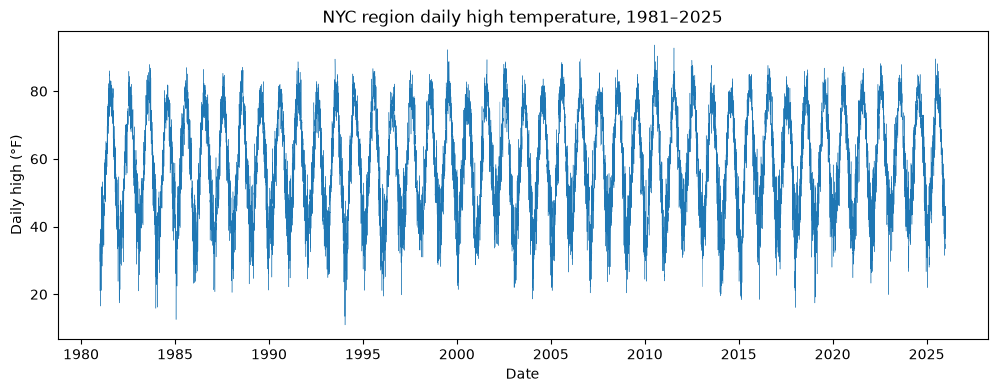

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["T2M_MAX_F"], linewidth=0.3)
ax.set_title("NYC region daily high temperature, 1981–2025")
ax.set_xlabel("Date")
ax.set_ylabel("Daily high (°F)")
plt.show()

In [26]:
monthly = df.groupby("month")["T2M_MAX_F"].mean()
monthly

month
1     38.180181
2     39.236524
3     44.609690
4     53.254507
5     62.417652
6     72.021413
7     78.726774
8     78.331768
9     72.971960
10    63.293187
11    53.057013
12    43.768929
Name: T2M_MAX_F, dtype: float64

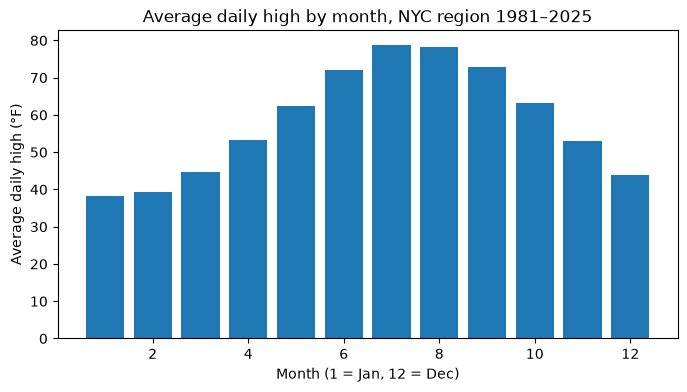

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthly.index, monthly.values)
ax.set_title("Average daily high by month, NYC region 1981–2025")
ax.set_xlabel("Month (1 = Jan, 12 = Dec)")
ax.set_ylabel("Average daily high (°F)")
plt.show()

In [28]:
df.loc["2024"].groupby("month")["T2M_MAX_F"].mean()

month
1     40.536645
2     41.388552
3     48.466516
4     53.618600
5     64.173548
6     74.828600
7     79.992065
8     78.387161
9     73.094000
10    66.994323
11    57.749000
12    43.822516
Name: T2M_MAX_F, dtype: float64

In [29]:
df.loc["2024", "T2M_MAX_F"].idxmax()

Timestamp('2024-08-28 00:00:00')

In [30]:
yearly_rain = df.groupby("year")["PRECTOTCORR"].sum() / 25.4
yearly_rain.head()

year
1981    39.001181
1982    40.808661
1983    63.568110
1984    53.607480
1985    38.090551
Name: PRECTOTCORR, dtype: float64

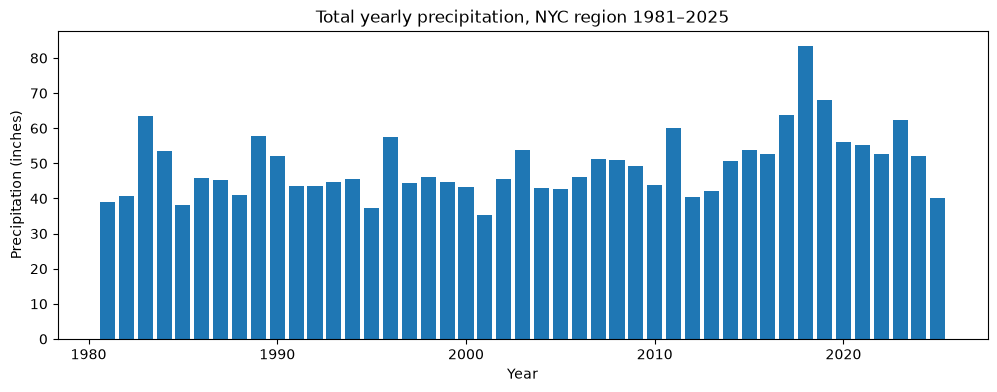

In [31]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(yearly_rain.index, yearly_rain.values)
ax.set_title("Total yearly precipitation, NYC region 1981–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Precipitation (inches)")
plt.show()

In [34]:
yearly_rain.idxmax()

np.int32(2018)

In [33]:
yearly_rain.idxmin()

np.int32(2001)

In [35]:
monthlyrain = df.groupby("month")["PRECTOTCORR"].sum()
monthlyrain

month
1     4471.85
2     3891.34
3     5115.38
4     4842.35
5     4788.35
6     4401.61
7     5295.49
8     4821.84
9     4564.10
10    4720.13
11    4392.70
12    5177.19
Name: PRECTOTCORR, dtype: float64

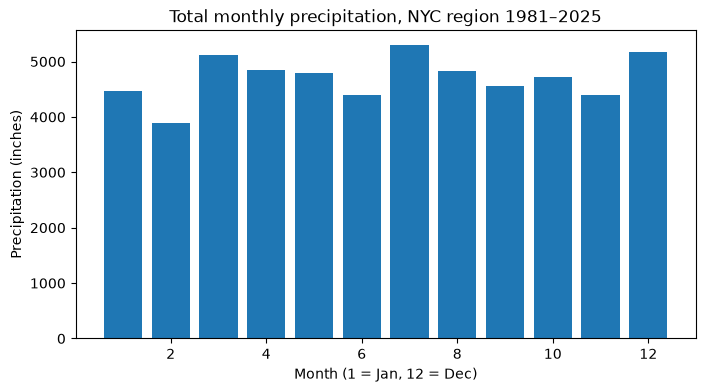

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthlyrain.index, monthlyrain.values)
ax.set_title("Total monthly precipitation, NYC region 1981–2025")
ax.set_xlabel("Month (1 = Jan, 12 = Dec)")
ax.set_ylabel("Precipitation (inches)")
plt.show()